# 3. PyTorch Computer Vision  

online textbook version: https://www.learnpytorch.io/03_pytorch_computer_vision/



If you want to see more about machine learning, you can goto the following websites:
- https://machinelearning.apple.com/
- https://www.tesla.com/SI
- https://viso.ai/applications/computer-vision-applications/

## 0. Computer vision libraries in PyTorch

- [`torchvision`](https://docs.pytorch.org/vision/stable/index.html) - base domain library for PyTorch computer vision
- `torchvision.datasets` - get datasets and data loading functions for computer vision here
- `torchvision.models` - get pretrained computer vision models that we can leverage for our own problems
- `torchvision.transforms` - functions for manipulating our vision data (images) to be suitable for use with ML model
- `torch.utils.data.Dataset` - Base dataset class for PyTorch
- `torch.utils.data.DataLoader` - Create a Python iterable over a dataset

In [ ]:
# Import PyTorch
import torch
from torch import nn

# Import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


## 1. Getting a dataset  

The dataset we are going to use is [`FashionMNIST`](https://github.com/zalandoresearch/fashion-mnist)  

A very foundamental dataset in computer vision is [`MNIST`](https://en.wikipedia.org/wiki/MNIST_database)  

We want to download the dataset through [`torchvision.datasets`](https://docs.pytorch.org/vision/stable/datasets.html)

In [ ]:
# Setup training data
train_data = torchvision.datasets.FashionMNIST(
    root="data",    # This ia a relative path
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

# Setup testing data
test_data = torchvision.datasets.FashionMNIST(
    root="data",    # This ia a relative path
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)



100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.3MB/s]


### 1.1 Check the features of the data

In [ ]:
# Look up the length of data
len(train_data), len(test_data)

(60000, 10000)

In [ ]:
# See first training sample
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
# Check the mapping between object and labels
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [ ]:
# Check the labels of the dataset
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [ ]:
# Check the shape of our image
print(f"Image shape: {image.shape} -> [color_channels, height, width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Image label: Ankle boot


### 1.2 Visualizing our data

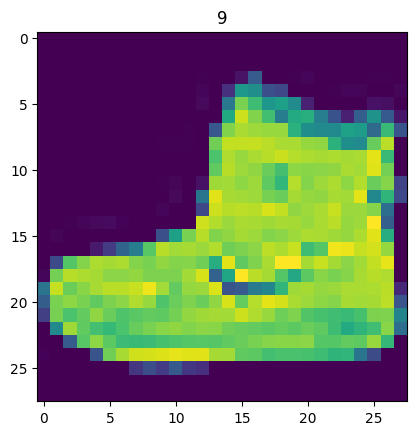

In [ ]:
plt.imshow(image.squeeze())
plt.title(label);

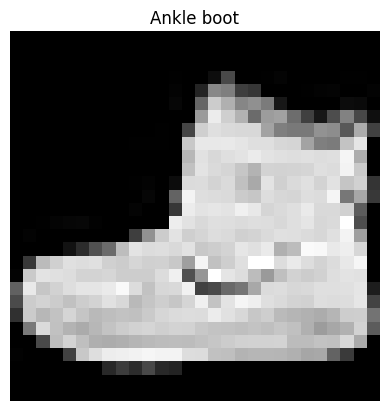

In [ ]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label]);
plt.axis(False);

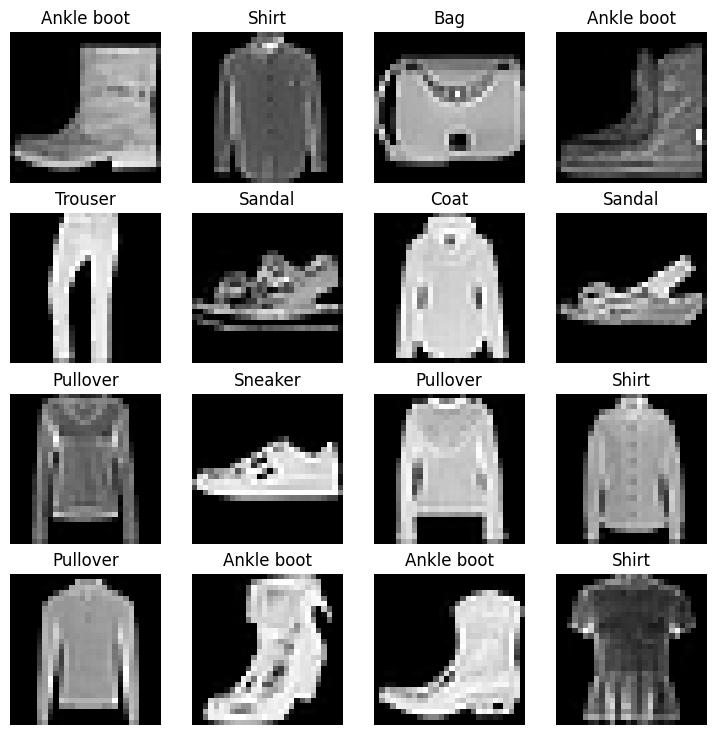

In [ ]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows*cols+1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  img, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(img.squeeze(), cmap="gray")
  plt.title(class_names[label])
  plt.axis(False);

Do you think these items of clothing (images) could be modelled with pure linear lines? Or do you think we'll need non-linearities?

## 2. Prepare DataLoader  

Right now, our data is in the form of PyTorch Datasets.  

DataLoader turns our dataset into a Python iterable.  

More specifically, we want to turn our data into batches (or mini-batches).  

- So what is a batch size?  

  Batch size is the number of training samples a model processes together in one forward-and-backward pass before updating its weights.

- Why should we do this?  

  1. It is more computationally efficient, as in, your computing hardware may not be able to look(store in memory) at 60000 images in one hit(otherwise your `VRAM` will explode). So we break it down to 32 image at a time (batch size of 32)  

  2. GPU is able to do calculation in parallel. If `batch_size = 1`(the batch size is very small), GPU is not sufficiently used.  

  3. `SGD` and `Adam` optimizer requires `batch_size` to create noise. But if the `batch_size` is too small then the noise is too large for the model to converge. In contrast, if the `batch_size` too large the there's no noise for the optimizer to jump out of the shallow point in loss landscape.

  4. It gives our neural network more chances to update  its gradients per epoch.  

If you want to learn more, you can go to - [Andrew Ng's opencourse on Mini‑Batch Gradient Descent](https://www.youtube.com/watch?v=4qJaSmvhxi8)  

And [`batch_size = 32`](https://x.com/ylecun/status/989610208497360896?s=20&t=N96J_jotN--PYuJk2WcjMw) is a good place to start for a fair amount of problems.  

But since this is a value you can set (a hyperparameter) you can try all different kinds of values, though generally powers of 2 are used most often (e.g. 32, 64, 128, 256, 512)

In [ ]:
# Create dataloader

from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Let's check out what we've create
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")


Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7eff37af5a90>, <torch.utils.data.dataloader.DataLoader object at 0x7eff344ce710>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [ ]:
# Check out what's inside the training dataloader
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


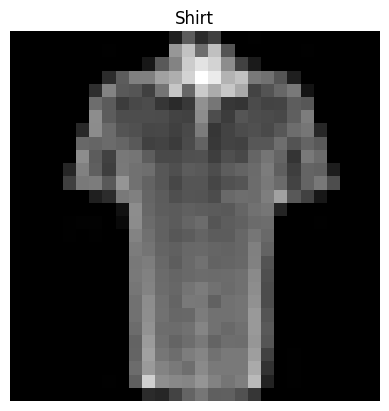

In [ ]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("Off");
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

## 3. Model_0: Build a baseline model  

Recall the basic building block of all neural network modules [`torch.nn.Module`](https://docs.pytorch.org/docs/2.15/generated/torch.nn.Module.html)  

A baseline model is one of the simplest models you can imagine.  

You can use the basline as a starting point and try to improve upon it with subsequent, more complicated models.  

Since we are working with image data, we are going to use a different layer to start things off.  

- [nn.Flatten()](https://docs.pytorch.org/docs/2.15/generated/torch.nn.modules.flatten.Flatten.html)

- [nn.Linear()](https://docs.pytorch.org/docs/2.15/generated/torch.nn.Linear.html)

- [nn.Conv()](https://docs.pytorch.org/docs/2.15/generated/torch.nn.modules.conv.Conv2d.html)







In [ ]:
# Create a flatten layer
flatten_model = nn.Flatten()

# Get a single sample
x = train_features_batch[0]

# Flatten the sample
output = flatten_model(x)

# Print out what happened
print(f"Shape before flattening:{x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening:{output.shape} -> [color_channels, height*width]")

Shape before flattening:torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening:torch.Size([1, 784]) -> [color_channels, height*width]


In [ ]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.Linear(in_features=hidden_units, out_features=output_shape)
    )

  def forward(self, x):
    return self.layer_stack(x)

In [ ]:
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

model_0 = FashionMNISTModelV0(
    input_shape=1,
    hidden_units=10,
    output_shape=len(class_names)
).to(device)

### 3.1 Setup loss, optimizer and evaluation metrics


In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [ ]:
# Import accuracy metric
from helper_functions import accuracy_fn

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    params=model_0.parameters(),
    lr=0.1
)

### 3.2 Creating a function to time our experiments   

Let's make a timing function to measure the time it takes our model to train on CPU versus using a GPU  

- [`timeit.defult_timer()`](https://docs.python.org/3/library/timeit.html#timeit.default_timer) function of Python

- [`timeit`](https://docs.python.org/3/library/timeit.html) module of Python





In [ ]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
  """Prints difference between start and end time

  Args:
    start (float): start time of computation (preferred in timeit format).
    end (float): End time of computation.
    device ([type], optional): Device that compute is running on. Defaults to None.

  Returns:
    float: time between start and end in seconds (higher is longer)
  """

  total_time = end - start
  print(f"Train time on {device}: {total_time:.3f} seconds")
  return total_time


### 3.3 Creating a training loop and training a model on batches of data

In [ ]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(42)
torch.cuda.manual_seed(42)
train_time_start_on_cpu = timer()

# Set the number of epochs
epochs = 3

# Create training and testing loop
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}\n-------")
  ### Training
  train_loss = 0
  #m Add a loop to loop through training batches
  for batch, (X_train, y_train) in enumerate(train_dataloader):
    model_0.train()
    y_train_pred = model_0(X_train)
    loss = loss_fn(y_train_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if batch % 4000 == 0:
      print(f"Looked at {batch * len(X_train)/len(train_dataloader.dataset)} samples")

    train_loss += loss

  # Divide total train loss by length of train dataloader(the length of batch)
  train_loss /= len(train_dataloader)

  ### Testing
  # Setup variables for accumulatively adding up loss and accuracy
  test_loss, test_acc = 0, 0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      y_test_pred =  model_0(X_test)
      test_loss += loss_fn(y_test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test, y_pred=y_test_pred.argmax(dim=1))

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  ## Print out what's happening
  print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

# Calculate training time
train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(
    start=train_time_start_on_cpu,
    end=train_time_end_on_cpu,
    device=str(next(model_0.parameters()).device)
)



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------


RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)

## 5. Setup device agnostic-code(for using a GPU if there is one)

[device-agnostic code](https://docs.pytorch.org/docs/2.15/notes/cuda.html#best-practices)

In [ ]:
# Setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 6. `Model_1`: Building a better model with non-linearity  

We have to introduce `nn.ReLU`



In [ ]:
# Import PyTorch
import torch
from torch import nn

# Import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


In [ ]:
# Setup training data
train_data = torchvision.datasets.FashionMNIST(
    root="data",    # This ia a relative path
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

# Setup testing data
test_data = torchvision.datasets.FashionMNIST(
    root="data",    # This ia a relative path
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.89MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 166kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.8MB/s]


In [ ]:
# Create a model with non-linear and linear layers
class FashionMNISTModelV1(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=output_shape),
    )

  def forward(self, x:torch.Tensor):
    return self.layer_stack(x)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(
    input_shape=784,
    hidden_units=10,
    output_shape=10
).to(device)
next(model_1.parameters()).device

device(type='cuda', index=0)

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.1
)

device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
# Create dataloader

from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Let's check out what we've create
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")


Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7bfa323d1950>, <torch.utils.data.dataloader.DataLoader object at 0x7bfa32532780>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [ ]:
from timeit import default_timer as Timer

def train_step(
    model: torch.nn.Module,
    train_dataloader: torch.utils.data.DataLoader,
    loss_fn: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    accuracy_fn,
    device: torch.device = device
):
  train_loss, train_acc = 0, 0
  model.to(device)
  model.train()
  for batch, (X_train, y_train) in enumerate(train_dataloader):
    X_train, y_train = X_train.to(device), y_train.to(device)

    y_train_pred = model(X_train)
    loss = loss_fn(y_train_pred, y_train)
    acc = accuracy_fn(
        y_true=y_train,
        y_pred=y_train_pred.argmax(dim=1)
    )
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += loss
    train_acc += acc

  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")

def test_step(
    model: torch.nn.Module,
    test_dataloader: torch.utils.data.DataLoader,
    loss_fn: torch.nn.Module,
    accuracy_fn,
    device: torch.device = device
):
  test_loss, test_acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      X_test, y_test = X_test.to(device), y_test.to(device)
      y_test_pred = model(X_test)
      test_loss += loss_fn(y_test_pred, y_test)
      test_acc += accuracy_fn(
          y_true=y_test,
          y_pred=y_test_pred.argmax(dim=1)
      )

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.5f}%")

def print_train_time(start: float, end: float, device: torch.device = None):
    """Prints difference between start and end time.

    Args:
        start (float): Start time of computation (preferred in timeit format).
        end (float): End time of computation.
        device ([type], optional): Device that compute is running on. Defaults to None.

    Returns:
        float: time between start and end in seconds (higher is longer).
    """
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

In [ ]:
torch.cuda.manual_seed(42)
torch.manual_seed(42)

from tqdm.auto import tqdm
train_time_start_on_gpu = Timer()

epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch:{epoch}\n-----------")
  train_step(
      model=model_1,
      train_dataloader=train_dataloader,
      loss_fn=loss_fn,
      optimizer=optimizer,
      accuracy_fn=accuracy_fn
  )
  test_step(
      test_dataloader=test_dataloader,
      model=model_1,
      loss_fn=loss_fn,
      accuracy_fn=accuracy_fn,
  )

  train_time_end_on_gpu = Timer()
  total_train_time_model_1 = print_train_time(
      start=train_time_start_on_gpu,
      end=train_time_end_on_gpu,
      device=device
  )

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:0
-----------
Train loss: 0.64607 | Train accuracy: 77.17%
Test loss: 0.53855 | Test accuracy: 80.76078%
Train time on cuda: 10.441 seconds
Epoch:1
-----------
Train loss: 0.48094 | Train accuracy: 82.94%
Test loss: 0.49390 | Test accuracy: 82.45807%
Train time on cuda: 20.396 seconds
Epoch:2
-----------
Train loss: 0.44689 | Train accuracy: 84.16%
Test loss: 0.45746 | Test accuracy: 83.98562%
Train time on cuda: 30.305 seconds


## 7. `Model_2`: Building a Convolutional Neural Network (CNN)   

It's time to create a [Convolutional Neural Network](https://en.wikipedia.org/wiki/Convolutional_neural_network)  

The model we are going to use is known as TinyVGG from the [CNN Explainer](https://poloclub.github.io/cnn-explainer/)  

A typical architecture:  
`Input layer -> [Convolutional layer -> activation layer -> pooling layer] -> Output layer`  

Where the contents of `[Convolutional layer -> activation layer -> pooling layer]` can be upscaled and repeated multiple times, depending on requirements.  

- [`nn.Conv2d`](https://docs.pytorch.org/docs/2.15/generated/torch.nn.modules.conv.Conv2d.html): Convolutional Layer

- [`nn.MaxPool2d`](https://docs.pytorch.org/docs/2.15/generated/torch.nn.MaxPool2d.html): Maxpool Layer

- [`nn.Flatten`](https://docs.pytorch.org/docs/2.15/generated/torch.nn.modules.flatten.Flatten.html): Flatten Layer

If you want to learn more about `Convolutional Neural Network` - [Andrew Ng's Deeplearning Course](https://www.bilibili.com/video/BV1Rf4y1b7NP/?spm_id_from=333.337.search-card.all.click&vd_source=fb26d6b0a85e937ac89c1d9e51b46e73)




In [ ]:
import torch
import torch.nn as nn
# Create a convolutional neural network
class FashionMNISTModelV2(nn.Module):
  """
  Model architecture copying TinyVGG from:
  https://poloclub.github.io/cnn-explainer/
  """
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.block_1 = nn.Sequential(
        nn.Conv2d(
            in_channels=input_shape,
            out_channels=hidden_units,
            kernel_size=3,
            stride=1,
            padding=1
        ),
        nn.ReLU(),
        nn.Conv2d(
            in_channels=hidden_units,
            out_channels=hidden_units,
            kernel_size=3,
            stride=1,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )
    )
    self.block_2 = nn.Sequential(
        nn.Conv2d(
            in_channels=hidden_units,
            out_channels=hidden_units,
            kernel_size=3,
            stride=1,
            padding=1
        ),
        nn.ReLU(),
        nn.Conv2d(
            in_channels=hidden_units,
            out_channels=hidden_units,
            kernel_size=3,
            stride=1,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Dropout(p=0.5),
        nn.Linear(
            in_features=hidden_units*7*7,
            out_features=output_shape
        )
    )

  def forward(self, x: torch.Tensor):
    x = self.block_1(x)
    x = self.block_2(x)
    x = self.classifier(x)
    return x

In [ ]:
torch.manual_seed(42)
model_2 = FashionMNISTModelV2(
    input_shape=1,
    hidden_units=10,
    output_shape=len(class_names)
).to(device)
model_2

FashionMNISTModelV2(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

### 7.1 Steping through `nn.Conv2d()`  

Question: What does the "2d" in `nn.Conv2d()` stand for?  

The 2d is for 2-dimensional data. As in, our images have two dimensions: height and width. Yes, there's color channel dimension but each of the color channel dimensions have two dimensions too: height and width.  

For other dimensional data (such as 1D for text or 3D for 3D objects) there's also `nn.Conv1d()` and `nn.Conv3d()`.

In [ ]:
# Create the data

## Set the random seed
torch.manual_seed(42)

## Create sample batch of random numbers with same size as image batch
images = torch.randn(size=(32, 3, 64, 64))
test_image = images[0]
print(f"Image batch shape: {images.shape} -> [batch_size, color_channels, height, width]")
print(f"Single image shape: {test_image.shape} -> [color_channels, height, width]")
print(f"Single image pixel values: \n{test_image}")



Image batch shape: torch.Size([32, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Single image shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Single image pixel values: 
tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609

In [ ]:
test_image.unsqueeze(dim=0).shape

torch.Size([1, 3, 64, 64])

The parameters in `nn.Conv2d()`:  

- `in_channels`(int) - Number of channels in the input image
- `out_channels`(int) - Number of channels produced by the convolution
- `kernel_size`(int or tuple) - Size of the convolving kernel/filter
- `stride`(int or tuple, optional) - How big of step the convolving kernel takes at a time. Default:1
- `padding`(int, tuple, str) - Padding added to all four sides of input. Default:0  

If you want to visualize the parameters, you can use [CNN Explainer Website](https://poloclub.github.io/cnn-explainer/)


In [ ]:
torch.manual_seed(42)

# Create a convolutional layer with same dimensions as TinyVGG
# (try changing any of the parameters and see what happens)
conv_layer = nn.Conv2d(
    in_channels=3,
    out_channels=10,
    kernel_size=3,
    stride=1,
    padding=1
)

In [ ]:
# Pass single image through the convolutional layer
conv_layer(test_image.unsqueeze(dim=0)).shape

torch.Size([1, 10, 64, 64])

In [ ]:
# Check out the conv_layer internal parameters
print(conv_layer.state_dict())

OrderedDict({'weight': tensor([[[[ 0.1471,  0.1597, -0.0451],
          [ 0.1768, -0.0422,  0.0388],
          [-0.0937,  0.1130,  0.1697]],

         [[-0.1412,  0.1673,  0.0360],
          [ 0.1422,  0.0261,  0.0928],
          [-0.0272,  0.1484,  0.0284]],

         [[-0.0898,  0.0491, -0.0887],
          [-0.0226, -0.0782,  0.1277],
          [-0.1519, -0.0887, -0.0543]]],


        [[[-0.1157,  0.0182, -0.1901],
          [ 0.1738, -0.1635,  0.1486],
          [ 0.0320, -0.0625,  0.1189]],

         [[ 0.0300,  0.1555,  0.0210],
          [-0.0607,  0.0517, -0.0522],
          [ 0.0810,  0.1718,  0.1112]],

         [[-0.0841,  0.1111,  0.0344],
          [ 0.0977, -0.1173, -0.1905],
          [-0.0744, -0.1476,  0.1579]]],


        [[[ 0.0554,  0.0797,  0.0609],
          [-0.0033,  0.1506, -0.1367],
          [ 0.0121, -0.1314,  0.0593]],

         [[-0.0663,  0.0590, -0.0401],
          [ 0.1596, -0.1141, -0.1148],
          [-0.1148,  0.1731,  0.0641]],

         [[ 0.1852, -

Look at that! A bunch of random numbers for a weight and bias tensor.  

Let's check up the shape of weight and bias tensors within `conv_layer`

In [ ]:
# Get shapes of weight and bias tensors within conv_layer
print(f"conv_layer weight shape: \n{conv_layer.weight.shape}")
print(f"\nconv_layer bias shape: \n{conv_layer.bias.shape}")

conv_layer weight shape: 
torch.Size([10, 3, 3, 3])

conv_layer bias shape: 
torch.Size([10])


### 7.2 Stepping through [`nn.MaxPool2d()`](https://docs.pytorch.org/docs/2.15/generated/torch.nn.MaxPool2d.html)  

Now let's check out what happens when we move data through `nn.MaxPool2d()`

In [ ]:
test_image.shape

torch.Size([3, 64, 64])

In [ ]:
# Print out original image shape without and with unsqueezed dimension
print(f"Test image original shape: {test_image.shape}")
print(f"Test image with unsqueezed dimension: {test_image.unsqueeze(dim=0).shape}")

# Create a sample nn.MaxPoo2d() layer
max_pool_layer = nn.MaxPool2d(kernel_size=4)

# Pass data through just the conv_layer
test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"Shape after going through conv_layer(): {test_image_through_conv.shape}")

# Pass data through the max pool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"Shape after going through conv_layer() and max_pool_layer(): {test_image_through_conv_and_max_pool.shape}")

Test image original shape: torch.Size([3, 64, 64])
Test image with unsqueezed dimension: torch.Size([1, 3, 64, 64])
Shape after going through conv_layer(): torch.Size([1, 10, 64, 64])
Shape after going through conv_layer() and max_pool_layer(): torch.Size([1, 10, 16, 16])


In [ ]:
torch.manual_seed(42)
# Create a random tensor with a similar number of dimensions to our images
random_tensor = torch.randn(size=(1, 1, 2, 2))
print(f"\nRandom tensor:\n{random_tensor}")
print(f"Random tensor shape: {random_tensor.shape}")

# Create a maxpool layer
max_pool_layer = nn.MaxPool2d(kernel_size=2)

# Pass the random tensor through the max pool layer
max_pool_tensor = max_pool_layer(random_tensor)
print(f"\nMax pool tensor:\n {max_pool_tensor}")
print(f"Max pool tensor shape: {max_pool_tensor.shape}")


Random tensor:
tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])
Random tensor shape: torch.Size([1, 1, 2, 2])

Max pool tensor:
 tensor([[[[0.3367]]]])
Max pool tensor shape: torch.Size([1, 1, 1, 1])


### 7.3 Creating Optimizer and Loss Function  

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    params=model_2.parameters(),
    lr=0.1
)

### 7.4 Training and Testing CNN

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Measure Time
from timeit import default_timer as Timer
train_time_start_model_2 = Timer()

# Train and Test Model
epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}\n---------")
  train_step(
      model=model_2,
      train_dataloader=train_dataloader,
      loss_fn=loss_fn,
      optimizer=optimizer,
      accuracy_fn=accuracy_fn,
      device=device
  )
  test_step(
      model=model_2,
      test_dataloader=test_dataloader,
      loss_fn=loss_fn,
      accuracy_fn=accuracy_fn,
      device=device
  )

train_time_end_model_2 = Timer()
total_train_time_model_2 = print_train_time(
    start=train_time_start_model_2,
    end=train_time_end_model_2,
    device=device
)



  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss: 0.21051 | Train accuracy: 92.30%
Test loss: 0.29857 | Test accuracy: 88.98762%
Epoch: 1
---------
Train loss: 0.21244 | Train accuracy: 92.15%
Test loss: 0.27865 | Test accuracy: 90.02596%
Epoch: 2
---------
Train loss: 0.20972 | Train accuracy: 92.27%
Test loss: 0.29532 | Test accuracy: 89.38698%
Epoch: 3
---------
Train loss: 0.20851 | Train accuracy: 92.31%
Test loss: 0.28289 | Test accuracy: 90.16573%
Epoch: 4
---------
Train loss: 0.20848 | Train accuracy: 92.32%
Test loss: 0.33031 | Test accuracy: 88.26877%
Epoch: 5
---------
Train loss: 0.20903 | Train accuracy: 92.42%
Test loss: 0.28722 | Test accuracy: 90.11581%
Epoch: 6
---------
Train loss: 0.20764 | Train accuracy: 92.39%
Test loss: 0.27753 | Test accuracy: 90.06589%
Epoch: 7
---------
Train loss: 0.20631 | Train accuracy: 92.47%
Test loss: 0.29004 | Test accuracy: 89.90615%
Epoch: 8
---------
Train loss: 0.20452 | Train accuracy: 92.53%
Test loss: 0.28969 | Test accuracy: 89.97604%
Epoch: 9
-